# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [4]:
df_mares_ano = pd.read_csv(DIR_RAW / "mares_2025.csv")

df_mares_prev = pd.read_csv(DIR_RAW / "mares_previsao.csv")

df_ondas = pd.read_csv(DIR_RAW / "ondas.csv")

df_vento = pd.read_csv(DIR_RAW / "vento.csv")

In [5]:
dfs = {
    "mares_2025.csv": df_mares_ano,
    "mares_previsao.csv": df_mares_prev,
    "ondas.csv": df_ondas,
    "vento.csv": df_vento,
}

In [6]:
for nome, df in dfs.items():
    print(f"{nome}: {len(df)} linhas e {len(df.columns)} colunas")

mares_2025.csv: 1410 linhas e 4 colunas
mares_previsao.csv: 120 linhas e 4 colunas
ondas.csv: 168 linhas e 5 colunas
vento.csv: 168 linhas e 5 colunas


In [7]:
for nome, df in dfs.items():
    print(f"Tipos de dados em {nome}")
    print()
    print(df.dtypes)
    print()

Tipos de dados em mares_2025.csv

data      str
hora      str
altura    str
tipo      str
dtype: object

Tipos de dados em mares_previsao.csv

data      str
hora      str
altura    str
tipo      str
dtype: object

Tipos de dados em ondas.csv

dia        int64
mes          str
hora         str
valor        str
direcao      str
dtype: object

Tipos de dados em vento.csv

dia        int64
mes          str
hora         str
valor      int64
direcao      str
dtype: object



In [8]:
for nome, df in dfs.items():
    print(f"Qualidade dos Dados: {nome}")
    print()
    
    nulos_por_coluna = df.isna().sum()
    print("Valores nulos por coluna:")
    print(nulos_por_coluna[nulos_por_coluna > 0] if nulos_por_coluna.sum() > 0 else "  Nenhum valor nulo encontrado.")
    
    total_duplicadas = df.duplicated().sum()
    print(f"Linhas duplicadas: {total_duplicadas}")
    print("-" * 40)

Qualidade dos Dados: mares_2025.csv

Valores nulos por coluna:
  Nenhum valor nulo encontrado.
Linhas duplicadas: 0
----------------------------------------
Qualidade dos Dados: mares_previsao.csv

Valores nulos por coluna:
  Nenhum valor nulo encontrado.
Linhas duplicadas: 0
----------------------------------------
Qualidade dos Dados: ondas.csv

Valores nulos por coluna:
  Nenhum valor nulo encontrado.
Linhas duplicadas: 0
----------------------------------------
Qualidade dos Dados: vento.csv

Valores nulos por coluna:
  Nenhum valor nulo encontrado.
Linhas duplicadas: 0
----------------------------------------


1.  Há 1410 linhas no arquivo 'mares_2025.csv', 120 em 'mares_previsao.csv' e 168 tanto em 'ondas.csv' quanto em 'vento.csv'. Sim, os números fazem total sentido de acordo com as especificações dadas. 
2. No geral, a maioria veio com um tipo diferente. O maior exemplo são os casos de tipo número que vieram como string.
3. Não foram encontrados nem valores nulos nem linhas duplicadas.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [9]:
df_mares_ano["datetime"] = pd.to_datetime(df_mares_ano["data"] + " " + df_mares_ano["hora"], format="%Y-%m-%d %H:%M")
df_mares_prev["datetime"] = pd.to_datetime(df_mares_prev["data"] + " " + df_mares_prev["hora"], format="%Y-%m-%d %H:%M")

MESES = {"JAN": 1, "FEV": 2, "MAR": 3, "ABR": 4, "MAI": 5, "JUN": 6,
         "JUL": 7, "AGO": 8, "SET": 9, "OUT": 10, "NOV": 11, "DEZ": 12}
ano_prev = df_mares_prev["datetime"].dt.year.iloc[0]

mes = df_ondas["mes"].str.upper().map(MESES)
df_ondas["datetime"] = (
    pd.to_datetime(pd.DataFrame({"year": ano_prev + (mes < mes.iloc[0]).astype(int), "month": mes, "day": df_ondas["dia"]}))
    + pd.to_timedelta(df_ondas["hora"] + ":00")
)

mes = df_vento["mes"].str.upper().map(MESES)
df_vento["datetime"] = (
    pd.to_datetime(pd.DataFrame({"year": ano_prev + (mes < mes.iloc[0]).astype(int), "month": mes, "day": df_vento["dia"]}))
    + pd.to_timedelta(df_vento["hora"] + ":00")
)

In [10]:
df_mares_ano["altura_m"] = pd.to_numeric(df_mares_ano["altura"].str.replace(",", ".", regex=False))
df_mares_prev["altura_m"] = pd.to_numeric(df_mares_prev["altura"].str.replace(",", ".", regex=False))
df_ondas["altura_m"] = pd.to_numeric(df_ondas["valor"].str.replace(",", ".", regex=False))
df_vento["velocidade_kmh"] = df_vento["valor"].astype(float)


df_mares_ano["tipo"] = df_mares_ano["tipo"].map({"pleamar": "alta", "bajamar": "baixa"})
df_mares_prev["tipo"] = df_mares_prev["tipo"].map({"pleamar": "alta", "bajamar": "baixa"})

df_ondas["direcao"] = df_ondas["direcao"].str.strip().str.upper()
df_vento["direcao"] = df_vento["direcao"].str.strip().str.upper()

In [11]:
df_mares_ano = df_mares_ano[["datetime", "tipo", "altura_m"]].sort_values("datetime").reset_index(drop=True)
df_mares_prev = df_mares_prev[["datetime", "tipo", "altura_m"]].sort_values("datetime").reset_index(drop=True)
df_ondas = df_ondas[["datetime", "altura_m", "direcao"]].sort_values("datetime").reset_index(drop=True)
df_vento = df_vento[["datetime", "velocidade_kmh", "direcao"]].sort_values("datetime").reset_index(drop=True)

dfs = {
    "mares_2025.csv": df_mares_ano,
    "mares_previsao.csv": df_mares_prev,
    "ondas.csv": df_ondas,
    "vento.csv": df_vento,
}

In [12]:
for nome, df in dfs.items():
    print(f"{nome}: {df.isna().sum().sum()} nulos, {df.duplicated('datetime').sum()} datetimes repetidos")

for nome in ["mares_2025.csv", "mares_previsao.csv"]:
    df = dfs[nome]
    assert (df["tipo"].values[1:] != df["tipo"].values[:-1]).all(), f"{nome}: alta e baixa não se alternam"
    assert df["altura_m"].between(0, 4).all(), f"{nome}: altura fora de 0-4 m"
for nome in ["ondas.csv", "vento.csv"]:
    assert (dfs[nome]["datetime"].diff().dropna() == pd.Timedelta(hours=1)).all(), f"{nome}: buraco na série horária"

for nome, df in dfs.items():
    print()
    print(nome, df.shape)
    print(df.dtypes.to_string())

mares_2025.csv: 0 nulos, 0 datetimes repetidos
mares_previsao.csv: 0 nulos, 0 datetimes repetidos
ondas.csv: 0 nulos, 0 datetimes repetidos
vento.csv: 0 nulos, 0 datetimes repetidos

mares_2025.csv (1410, 3)
datetime    datetime64[us]
tipo                   str
altura_m           float64

mares_previsao.csv (120, 3)
datetime    datetime64[us]
tipo                   str
altura_m           float64

ondas.csv (168, 3)
datetime    datetime64[us]
altura_m           float64
direcao                str

vento.csv (168, 3)
datetime          datetime64[us]
velocidade_kmh           float64
direcao                      str


1. Sim, data e hora são convertidos para datetime. Essa escolha é válida para facilitar a análise da pergunta inicial. ALém disso, como serão realizadas filtragens e merges, tal ação facilita a visualização gráfica.
2. Essa problemática foi resolvida aqui, por meio do uso do replace.
3. Não foram identificados.
4. Não foram identificadas.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

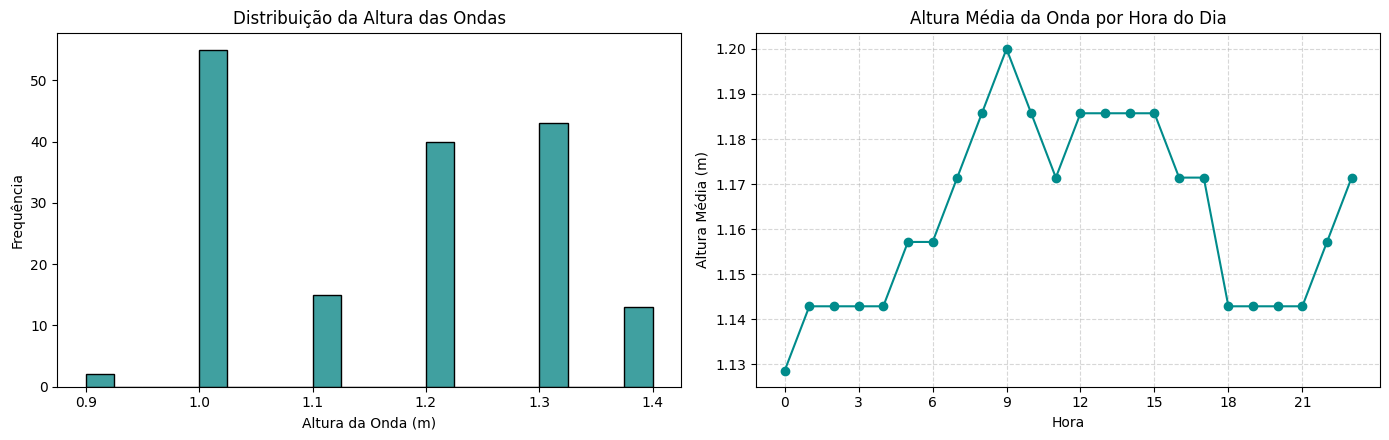

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))


sns.histplot(data=df_ondas, x="altura_m", bins=20, ax=ax1, color="teal")
ax1.set_title("Distribuição da Altura das Ondas")
ax1.set_xlabel("Altura da Onda (m)")
ax1.set_ylabel("Frequência")


df_ondas["hora_dia"] = df_ondas["datetime"].dt.hour
media_hora_onda = df_ondas.groupby("hora_dia")["altura_m"].mean()
ax2.plot(media_hora_onda.index, media_hora_onda.values, marker="o", color="darkcyan")
ax2.set_title("Altura Média da Onda por Hora do Dia")
ax2.set_xlabel("Hora")
ax2.set_ylabel("Altura Média (m)")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

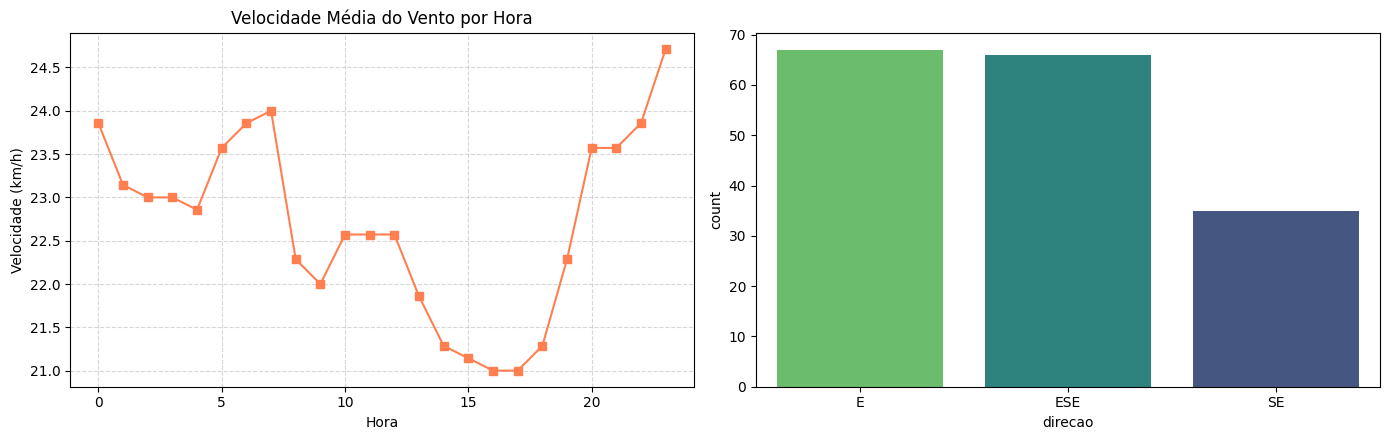

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

media_hora_vento = df_vento.groupby(df_vento["datetime"].dt.hour)["velocidade_kmh"].mean()
ax1.plot(media_hora_vento.index, media_hora_vento.values, marker="s", color="coral")
ax1.set_title("Velocidade Média do Vento por Hora")
ax1.set_xlabel("Hora")
ax1.set_ylabel("Velocidade (km/h)")
ax1.grid(True, linestyle="--", alpha=0.5)

sns.countplot(
    data=df_vento,
    x="direcao",
    hue="direcao",
    order=df_vento["direcao"].value_counts().index,
    ax=ax2,
    palette="viridis",
    legend=False,
)

plt.tight_layout()
plt.show()

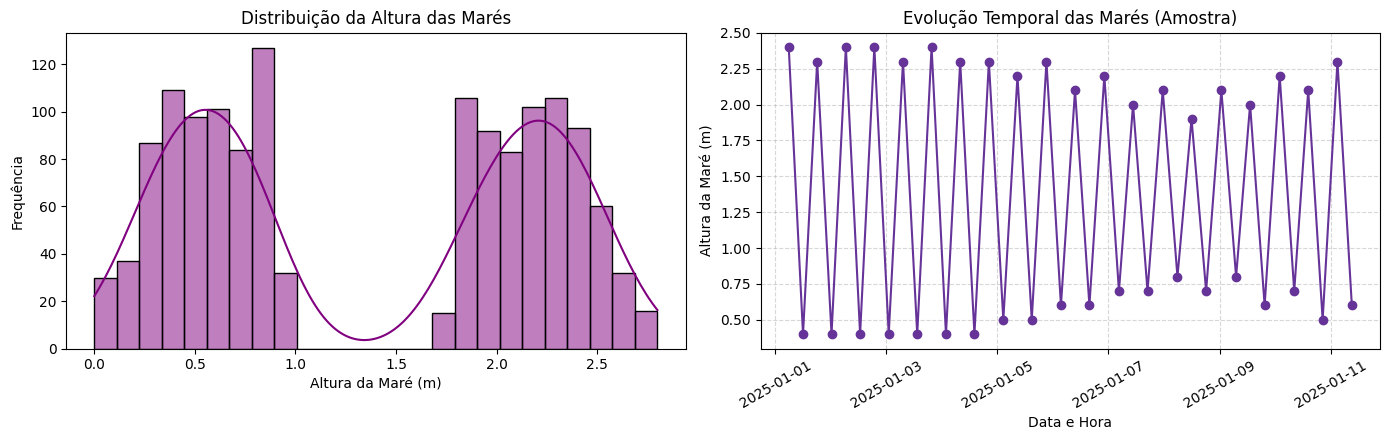

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=df_mares_ano, x="altura_m", bins=25, ax=ax1, color="purple", kde=True)
ax1.set_title("Distribuição da Altura das Marés")
ax1.set_xlabel("Altura da Maré (m)")
ax1.set_ylabel("Frequência")

amostra_mares = df_mares_ano.sort_values("datetime").head(40) 

ax2.plot(amostra_mares["datetime"], amostra_mares["altura_m"], marker="o", color="rebeccapurple", linestyle="-")
ax2.set_title("Evolução Temporal das Marés (Amostra)")
ax2.set_xlabel("Data e Hora")
ax2.set_ylabel("Altura da Maré (m)")
plt.xticks(rotation=30)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

1. Vê-se claramente que as ondas, de uma forma geral, apresentam uma altura relativamente estável, representando um comportamento expressivo em 1 e 1.3 metros. Além disso, foi possível perceber que as ondas possuem uma distribuição mais favorável para o surf durante o dia, uma vez que às 9h foi possível obter seu maior pico de altura (cerca de 1.20 m).
2. Percebe-se também uma boa distribuição dos ventos ao longo de um dia, cuja maior velocidade foi registrada no período após as 20h (cerca de 25 km/h). Além disso, pelo countplot, foi possível analisar que os ventos se direcionam majoritariamente para o Leste e Leste-Sudeste (representados pelos caracteres 'E' e 'ESE', respectivamente). 
3. Analisa-se que a distribuição da altura das marés ocorre de forma bimodal (em que são analisados dois picos ao longo da distribuição).

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [22]:
df_final = pd.merge(
    df_ondas,
    df_vento,
    on="datetime",
    suffixes=("_onda", "_vento")
)

mare = df_mares_prev.set_index("datetime")["altura_m"]

mare_horaria = mare.reindex(
    mare.index.union(df_final["datetime"])
).sort_index().interpolate(method="time")

df_final["altura_mare_m"] = (
    df_final["datetime"].map(mare_horaria)
)

df_final["hora_dia"] = df_final["datetime"].dt.hour
df_final["hora"] = df_final["hora_dia"]
df_final["data"] = df_final["datetime"].dt.strftime("%Y-%m-%d")
df_final["mes"] = df_final["datetime"].dt.month

dias = {
    0: "Segunda-feira", 1: "Terça-feira",
    2: "Quarta-feira", 3: "Quinta-feira",
    4: "Sexta-feira", 5: "Sábado", 6: "Domingo"
}

df_final["dia_semana"] = df_final["datetime"].dt.dayofweek.map(dias)


df_final["variacao_mare"] = df_final["altura_mare_m"].diff()

df_final["mare_subindo"] = np.where(
    df_final["variacao_mare"] > 0, "subindo",
    np.where(
        df_final["variacao_mare"] < 0,
        "descendo",
        "estável ou indeterminada"
    )
)

df_final = df_final[[
    "datetime", "altura_m", "direcao_onda",
    "hora_dia", "velocidade_kmh", "direcao_vento",
    "altura_mare_m", "variacao_mare", "mare_subindo",
    "hora", "dia_semana", "data", "mes"
]]

2026-10-01 00:24:00
2026-10-31 20:58:00
2026-10-09 00:00:00
2026-10-15 23:00:00


Inicialmente, gostaria de ressaltar que fiz um uso majoritário de Inteligência Artificial nesta seção. Em suma, foi realizado um merge entre os dados de ondas e ventos, enquanto os dados relativos às marés foram tratados a partir de uma interpolação linear temporal, a fim de preencher as horas vazias com valores estimados. Posteriormente, foi-se realizado o cálculo da variação da maré, por meio do .diff(), com o objetivo de classificar dinamicamente o nível da água (que pode ser utilizado para futuras análises).

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

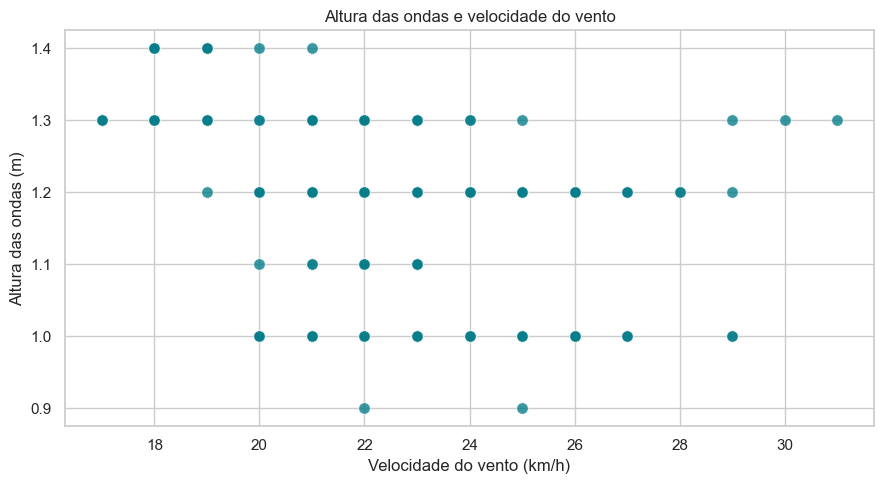

Correlação entre ondas e vento: -0.370


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_final,
    x="velocidade_kmh",
    y="altura_m",
    s=70,
    color="#087E8B",
    alpha=0.8
)

plt.title("Altura das ondas e velocidade do vento")
plt.xlabel("Velocidade do vento (km/h)")
plt.ylabel("Altura das ondas (m)")
plt.tight_layout()
plt.show()

correlacao = df_final[
    ["altura_m", "velocidade_kmh"]
].corr().iloc[0, 1]

print(f"Correlação entre ondas e vento: {correlacao:.3f}")


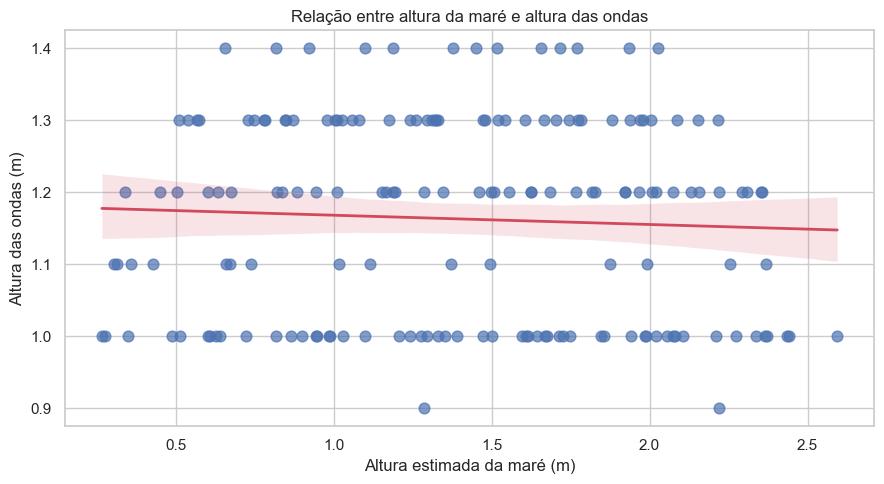

Correlação entre maré e ondas: -0.054


In [24]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_final,
    x="altura_mare_m",
    y="altura_m",
    scatter_kws={"s": 60, "alpha": 0.7},
    line_kws={"color": "#D1495B", "linewidth": 2}
)

plt.title("Relação entre altura da maré e altura das ondas")
plt.xlabel("Altura estimada da maré (m)")
plt.ylabel("Altura das ondas (m)")
plt.tight_layout()
plt.show()

correlacao_mare = df_final[
    ["altura_mare_m", "altura_m"]
].corr().iloc[0, 1]

print(
    "Correlação entre maré e ondas:",
    round(correlacao_mare, 3)
)


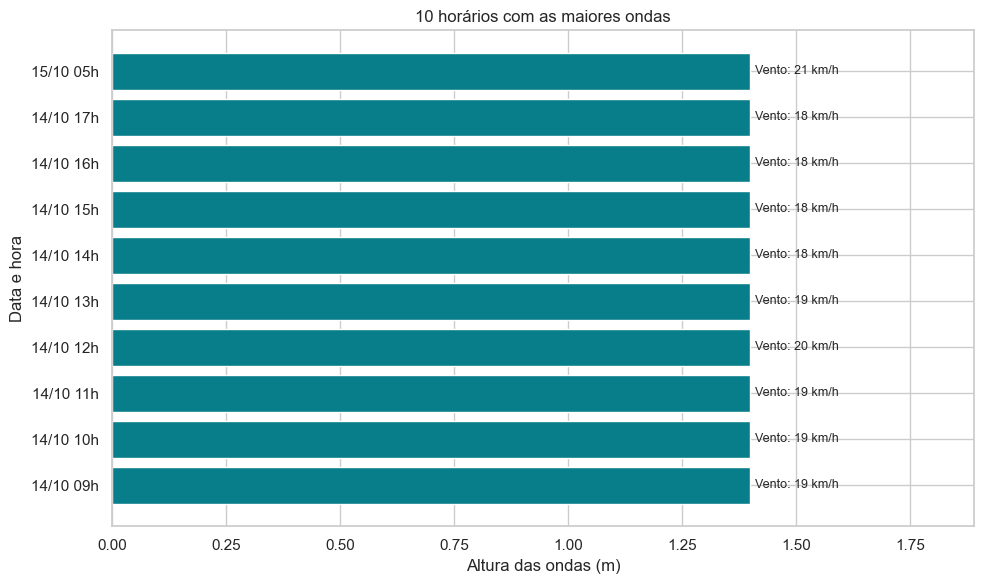

           datetime  altura_m  velocidade_kmh  altura_mare_m
2026-10-14 09:00:00       1.4            19.0       1.657260
2026-10-14 10:00:00       1.4            19.0       1.377808
2026-10-14 11:00:00       1.4            19.0       1.098356
2026-10-14 12:00:00       1.4            20.0       0.818904
2026-10-14 13:00:00       1.4            19.0       0.657300
2026-10-14 14:00:00       1.4            18.0       0.921763
2026-10-14 15:00:00       1.4            18.0       1.186226
2026-10-14 16:00:00       1.4            18.0       1.450689
2026-10-14 17:00:00       1.4            18.0       1.715152
2026-10-15 05:00:00       1.4            21.0       1.515467


In [25]:
top_10 = (
    df_final.nlargest(10, "altura_m")
    .sort_values("altura_m")
    .copy()
)

top_10["momento"] = top_10["datetime"].dt.strftime(
    "%d/%m %Hh"
)

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    top_10["momento"],
    top_10["altura_m"],
    color="#087E8B"
)

ax.set_title("10 horários com as maiores ondas")
ax.set_xlabel("Altura das ondas (m)")
ax.set_ylabel("Data e hora")

for barra, velocidade in zip(
    barras, top_10["velocidade_kmh"]
):
    ax.text(
        barra.get_width() + 0.01,
        barra.get_y() + barra.get_height() / 2,
        f"Vento: {velocidade:.0f} km/h",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    top_10["altura_m"].max() * 1.35
)

plt.tight_layout()
plt.show()

print(
    top_10[
        ["datetime", "altura_m", "velocidade_kmh",
         "altura_mare_m"]
    ].sort_values("altura_m", ascending=False).to_string(
        index=False
    )
)

1. Há uma leve correlação negativa entre ondas e ventos (cerca de -0.370), indicando que, de uma forma geral, os momentos em que as ondas atigem maior altura tendem a coincidir com ventos mais amenos (o que, de certa forma, é válido para os surfirtas).
2. Vê-se que quase não há correlação entre a altura da maré e a altura das ondas (cerca de -0.054). Dessa forma, chega-se à conclusão de que as ondas grandes aparecem independentemente de a maré estar secando ou enchendo.
3. Pelo terceiro gráfico, observa-se notadamente que os dias 14 e 15 de outubro possuem os melhores registros para o surf. Isso porque as ondas apresentarão uma excelente altura (em torno de 1.4 m) e ventos extremamente favoráveis para a prática desse esporte (cerca de 20 km/h).

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [27]:
caminho_saida = DIR_PROC / "dataset.csv"

df_merged.to_csv(caminho_saida, index=False, encoding="utf-8")

Dataset guardado com sucesso em: ..\data\processed\dataset.csv


## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

1. Como descrito na seção 5, as alturas das ondas concentram-se de forma estável entre 1.0 m e 1.4 m, com picos expressivos nos dias 14 e 15 de outubro de 2026, onde atingem consistentemente o teto de 1.4 m. Além disso, chegou-se à conclusão de que a velocidade dos ventos nem o nível da maré afetam de forma direta o desenvolvimento das ondas, as quais podem ser desenvolvidas por outros fatores externos.
2. A interpolação temporal dos dados de maré, isso porque s dados brutos de maré fornecidos inicialmente continham apenas os extremos astronómicos (preia-mar e baixa-mar). Se os dados fossem mantidos sem tratamento, a tabela horária ficaria cheia de valores vazios (NaN). A interpolação linear permitiu preencher matematicamente as horas intermediárias de forma suave, viabilizando que o modelo cruzasse simultaneamente vento, onda e maré para cada hora da janela de outubro.
3. Acredito que a principal lacuna seja a questão do tempo. Como foram obtidos apenas os dados referentes a 2026, não se tem um panorama geral acerca dos melhores períodos e estações para essa prática. Além disso, a metereologia se configura como um campo muito extenso. As deduções matemáticas aqui realizadas não constituem verdades que possam substituir o conhecimento físico e climático